#### Template repetition formal experiment

In [1]:
import importlib, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.sparse import save_npz
from sklearn.metrics import pairwise_distances
from time import perf_counter

import src.paths as paths
import src.io_utils as io_utils
import src.defects as defects
import src.metrics as metrics
import src.representations as representations

importlib.reload(paths)
importlib.reload(io_utils)
importlib.reload(defects)
importlib.reload(metrics)
importlib.reload(representations)

from src.paths import get_project_paths
from src.io_utils import stratified_disjoint_pair_indices
from src.representations import make_tfidf_vectorizer
from src.metrics import c2st_paired, mmd_paired_permutation_test, energy_paired_permutation_test, sinkhorn_divergence, sinkhorn_paired_permutation_test

PATHS=get_project_paths()
DATA_DIR=PATHS["processed"]
RESULTS_DIR=PATHS["results"]
WEEK7_RESULTS_DIR=RESULTS_DIR/"week7"
WEEK7_RESULTS_DIR.mkdir(parents=True,exist_ok=True)

In [2]:
# cexperiment configuration 
import importlib, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.sparse import save_npz
from sklearn.metrics import pairwise_distances
from time import perf_counter

import src.paths as paths
import src.io_utils as io_utils
import src.defects as defects
import src.metrics as metrics
import src.representations as representations

importlib.reload(paths)
importlib.reload(io_utils)
importlib.reload(defects)
importlib.reload(metrics)
importlib.reload(representations)

from src.paths import get_project_paths
from src.io_utils import stratified_disjoint_pair_indices
from src.representations import make_tfidf_vectorizer
from src.metrics import c2st_paired, mmd_paired_permutation_test, energy_paired_permutation_test, sinkhorn_divergence, sinkhorn_paired_permutation_test

PATHS=get_project_paths()
DATA_DIR=PATHS["processed"]
RESULTS_DIR=PATHS["results"]
WEEK7_RESULTS_DIR=RESULTS_DIR/"week7"
WEEK7_RESULTS_DIR.mkdir(parents=True,exist_ok=True)

In [3]:
# reuse frozen sms split
TEMPLATE_REPS=200
TEMPLATE_N_PAIRS=100
TEMPLATE_PERMUTATIONS=100
TEMPLATE_ALPHA=0.05
TEMPLATE_SEVERITIES=[0.10,0.30,0.60]
TEMPLATE_SAMPLE_BASE_SEED=42
TEMPLATE_PLAN_SEED=42
TEMPLATE_TEST_BASE_SEED=10000


In [5]:
# reuse frozen splits 
raw_path=PATHS["root"]/"data"/"raw"/"SMSSpamCollection"
sms=pd.read_csv(raw_path,sep="\t",header=None,names=["label","text"])
sms["message_id"]=[f"SMS_{i:04d}" for i in range(len(sms))]

split=pd.read_csv(DATA_DIR/"over_polished_sms_split.csv")
print(split.columns.tolist())

['label', 'text', 'message_id', 'split']


In [6]:
# merge og text message id
split_meta=split.drop(columns=["text"],errors="ignore")
template_sms=split_meta.merge(sms[["message_id","label","text"]],on=["message_id","label"],how="left",validate="one_to_one")

assert template_sms["text"].notna().all()

template_ref=template_sms.loc[template_sms["split"]=="reference"].copy().reset_index(drop=True)
template_eval=template_sms.loc[template_sms["split"]=="evaluation"].copy().reset_index(drop=True)

print("Reference:",template_ref.shape)
print(template_ref["label"].value_counts())
print("\nEvaluation:",template_eval.shape)
print(template_eval["label"].value_counts())

Reference: (700, 4)
label
ham     606
spam     94
Name: count, dtype: int64

Evaluation: (300, 4)
label
ham     260
spam     40
Name: count, dtype: int64


In [7]:
importlib.reload(defects)
from src.defects import make_template_repetition_plan,apply_template_repetition_plan

template_plan=make_template_repetition_plan(template_eval,template_ref,severities=TEMPLATE_SEVERITIES,seed=TEMPLATE_PLAN_SEED)
display(template_plan.groupby(["severity","label"]).size())

severity  label
0.1       ham       26
          spam       4
0.3       ham       78
          spam      12
0.6       ham      156
          spam      24
dtype: int64

In [8]:
# nesting validation 
affected={s:set(template_plan.loc[np.isclose(template_plan["severity"],s),"message_id"]) for s in TEMPLATE_SEVERITIES}

for s in TEMPLATE_SEVERITIES: print(f"{s:.0%} | affected =",len(affected[s]))

assert affected[0.10].issubset(affected[0.30])
assert affected[0.30].issubset(affected[0.60])

print("Nested plan passed.")

10% | affected = 30
30% | affected = 90
60% | affected = 180
Nested plan passed.


In [10]:
# insoect fixed templates 
display(template_plan[["label","template_source_id","template_text"]].drop_duplicates())

,label,template_source_id,template_text
0,ham,SMS_2075,Yar lor actually we quite fast... Cos da ge sl...
26,spam,SMS_2583,3 FREE TAROT TEXTS! Find out about your love l...


In [13]:
# build clean and defectivew conditions
template_conditions={"clean":template_eval.copy()}
for s in TEMPLATE_SEVERITIES: template_conditions[s]=apply_template_repetition_plan(template_eval,template_plan,s)

for s in TEMPLATE_SEVERITIES:
    changed=(template_conditions[s]["text"].to_numpy()!=template_eval["text"].to_numpy())
    print(f"{s:.0%} | changed={changed.sum()} | expected={len(affected[s])}")
    assert changed.sum()==len(affected[s])

10% | changed=30 | expected=30
30% | changed=90 | expected=90
60% | changed=180 | expected=180


In [14]:
# validate ids and class labels
clean_ids=template_eval["message_id"].to_numpy()

for s in TEMPLATE_SEVERITIES:
    df=template_conditions[s]
    assert np.array_equal(df["message_id"].to_numpy(),clean_ids)
    assert np.array_equal(df["label"].to_numpy(),template_eval["label"].to_numpy())

print("ID and label alignment passed.")

ID and label alignment passed.


In [15]:
# check duplicate rate response
def repetition_summary(df):
    return {"messages":len(df),"unique_messages":df["text"].nunique(),"duplicate_rate":df["text"].duplicated().mean()}

rep_summary=pd.DataFrame({"clean":repetition_summary(template_eval),**{f"{s:.0%}":repetition_summary(template_conditions[s]) for s in TEMPLATE_SEVERITIES}}).T
display(rep_summary)

,messages,unique_messages,duplicate_rate
clean,300.0,292.0,0.026667
10%,300.0,265.0,0.116667
30%,300.0,206.0,0.313333
60%,300.0,118.0,0.606667


In [16]:
# save defect plan
template_plan.to_csv(DATA_DIR/"template_repetition_formal_plan.csv",index=False)
template_eval[["message_id","label"]].to_csv(DATA_DIR/"template_repetition_formal_eval_ids.csv",index=False)
print("Formal template plan saved.")

Formal template plan saved.


In [17]:
# fit tf idf on clean reference only 
vectorizer=make_tfidf_vectorizer()

X_template_ref_sparse=vectorizer.fit_transform(template_ref["text"])
X_template_clean_sparse=vectorizer.transform(template_eval["text"])

print("Reference:",X_template_ref_sparse.shape)
print("Clean evaluation:",X_template_clean_sparse.shape)
print("Vocabulary:",len(vectorizer.vocabulary_))

Reference: (700, 5000)
Clean evaluation: (300, 5000)
Vocabulary: 5000


In [18]:
# transform all defectiv conditions
X_template_sparse={"clean":X_template_clean_sparse}

for s in TEMPLATE_SEVERITIES:
    X_template_sparse[s]=vectorizer.transform(template_conditions[s]["text"])
    print(f"{s:.0%}:",X_template_sparse[s].shape)

10%: (300, 5000)
30%: (300, 5000)
60%: (300, 5000)


In [19]:
# save sparse tf idf artifacts 
save_npz(DATA_DIR/"template_tfidf_reference.npz",X_template_ref_sparse)
save_npz(DATA_DIR/"template_tfidf_clean.npz",X_template_sparse["clean"])

for s in TEMPLATE_SEVERITIES: save_npz(DATA_DIR/f"template_tfidf_{int(s*100)}pct.npz",X_template_sparse[s])

print("TF-IDF artifacts saved.")

TF-IDF artifacts saved.


In [20]:
# derive clean only geometric scale
D_ref=pairwise_distances(X_template_ref_sparse,metric="euclidean")
upper=D_ref[np.triu_indices(len(D_ref),k=1)]
TEMPLATE_CLEAN_SCALE=float(np.median(upper))
TEMPLATE_MMD_SIGMA=TEMPLATE_CLEAN_SCALE
TEMPLATE_SINKHORN_BLUR=0.10*TEMPLATE_CLEAN_SCALE

print("Median clean TF-IDF distance:",TEMPLATE_CLEAN_SCALE)
print("Frozen MMD sigma:",TEMPLATE_MMD_SIGMA)
print("Frozen Sinkhorn blur:",TEMPLATE_SINKHORN_BLUR)

Median clean TF-IDF distance: 1.414213562373095
Frozen MMD sigma: 1.414213562373095
Frozen Sinkhorn blur: 0.1414213562373095


In [21]:
# convert evaluation arrays to float32
X_template={k:v.toarray().astype(np.float32) for k,v in X_template_sparse.items()}
X_template_ref=X_template_ref_sparse.toarray().astype(np.float32)

for k,X in X_template.items(): print(k,X.shape,X.dtype)

clean (300, 5000) float32
0.1 (300, 5000) float32
0.3 (300, 5000) float32
0.6 (300, 5000) float32


In [22]:
# sinkhorn identity check
identity=sinkhorn_divergence(X_template["clean"][:100],X_template["clean"][:100],blur=TEMPLATE_SINKHORN_BLUR)
print("S(X,X):",f"{identity:.12e}")

S(X,X): 0.000000000000e+00


In [ ]:
def metric_record(metric,result,runtime):
    stat=result.get("statistic",result.get("accuracy"))
    reject=result.get("reject",result.get("reject_H0"))
    row={"metric":metric,"statistic":float(stat),"p_value":float(result["p_value"]),"reject":bool(reject),"runtime_seconds":runtime}
    if "null_mean" in result: row["null_mean"]=float(result["null_mean"])
    if "null_std" in result: row["null_std"]=float(result["null_std"])
    return row

In [24]:
def run_template_metrics(P,Q,seed):
    rows=[]
    start=perf_counter(); r=c2st_paired(P,Q,test_size=0.5,n_permutations=TEMPLATE_PERMUTATIONS,seed=seed,alpha=TEMPLATE_ALPHA); rows.append(metric_record("C2ST",r,perf_counter()-start))
    start=perf_counter(); r=mmd_paired_permutation_test(P,Q,sigma=TEMPLATE_MMD_SIGMA,n_permutations=TEMPLATE_PERMUTATIONS,seed=seed,alpha=TEMPLATE_ALPHA); rows.append(metric_record("MMD",r,perf_counter()-start))
    start=perf_counter(); r=energy_paired_permutation_test(P,Q,n_permutations=TEMPLATE_PERMUTATIONS,seed=seed,alpha=TEMPLATE_ALPHA); rows.append(metric_record("Energy",r,perf_counter()-start))
    start=perf_counter(); r=sinkhorn_paired_permutation_test(P,Q,blur=TEMPLATE_SINKHORN_BLUR,n_permutations=TEMPLATE_PERMUTATIONS,seed=seed,alpha=TEMPLATE_ALPHA); rows.append(metric_record("Sinkhorn",r,perf_counter()-start))
    return rows

In [25]:
# formal paired clen null
template_labels=template_eval["label"].to_numpy()
null_records=[]
start=perf_counter()

for rep in range(TEMPLATE_REPS):
    p_idx,q_idx=stratified_disjoint_pair_indices(template_labels,n_pairs=TEMPLATE_N_PAIRS,seed=42000+rep)
    P=X_template["clean"][p_idx]
    Q=X_template["clean"][q_idx]
    rows=run_template_metrics(P,Q,TEMPLATE_TEST_BASE_SEED+rep)
    for row in rows: null_records.append({"repetition":rep,**row})
    if (rep+1)%20==0: print(f"Completed {rep+1}/{TEMPLATE_REPS}")

template_null_runtime=perf_counter()-start
template_null_runs=pd.DataFrame(null_records)

print("Runtime:",round(template_null_runtime/60,2),"minutes")

Completed 20/200
Completed 40/200
Completed 60/200
Completed 80/200
Completed 100/200
Completed 120/200
Completed 140/200
Completed 160/200
Completed 180/200
Completed 200/200
Runtime: 18.23 minutes


In [26]:
template_null_summary=template_null_runs.groupby("metric").agg(repetitions=("reject","size"),rejections=("reject","sum"),type_I_error=("reject","mean"),mean_p_value=("p_value","mean"),median_p_value=("p_value","median"),mean_statistic=("statistic","mean"),std_statistic=("statistic","std"),mean_runtime_seconds=("runtime_seconds","mean")).reset_index()
display(template_null_summary)

,metric,repetitions,rejections,type_I_error,mean_p_value,median_p_value,mean_statistic,std_statistic,mean_runtime_seconds
0,C2ST,200,6,0.030,0.518960,0.539604,0.508650,0.050322,0.083318
1,Energy,200,9,0.045,0.520297,0.549505,-0.000164,0.001288,0.082956
2,MMD,200,9,0.045,0.515248,0.549505,-0.000053,0.000474,0.107966
3,Sinkhorn,200,9,0.045,0.537030,0.549505,0.748716,0.012814,5.189329


In [27]:
template_null_runs.to_csv(WEEK7_RESULTS_DIR/"template_formal_null_runs.csv",index=False)
template_null_summary.to_csv(WEEK7_RESULTS_DIR/"template_formal_null_summary.csv",index=False)

In [32]:
template_power_records=[]
start=perf_counter()

for rep in range(TEMPLATE_REPS):
    rng=np.random.default_rng(TEMPLATE_SAMPLE_BASE_SEED+rep)
    idx=rng.choice(len(template_eval),size=TEMPLATE_N_PAIRS,replace=False)
    sampled_ids=clean_ids[idx]
    P=X_template["clean"][idx]

    for severity in TEMPLATE_SEVERITIES:
        Q=X_template[severity][idx]
        n_affected=sum(mid in affected[severity] for mid in sampled_ids)
        rows=run_template_metrics(P,Q,TEMPLATE_TEST_BASE_SEED+rep)
        for row in rows: template_power_records.append({"repetition":rep,"severity":severity,"n_pairs":TEMPLATE_N_PAIRS,"n_affected":n_affected,"sample_affected_rate":n_affected/TEMPLATE_N_PAIRS,**row})

    if (rep+1)%20==0: print(f"Completed {rep+1}/{TEMPLATE_REPS} | elapsed {round((perf_counter()-start)/60,1)} min")

template_power_runtime=perf_counter()-start
template_power_runs=pd.DataFrame(template_power_records)

print("Rows:",len(template_power_runs))
print("Expected:",TEMPLATE_REPS*len(TEMPLATE_SEVERITIES)*4)
print("Runtime:",round(template_power_runtime/60,2),"minutes")


Completed 20/200 | elapsed 3.4 min
Completed 40/200 | elapsed 6.0 min
Completed 60/200 | elapsed 8.4 min
Completed 80/200 | elapsed 11.6 min
Completed 100/200 | elapsed 15.0 min
Completed 120/200 | elapsed 18.4 min
Completed 140/200 | elapsed 21.6 min
Completed 160/200 | elapsed 24.6 min
Completed 180/200 | elapsed 27.7 min
Completed 200/200 | elapsed 30.6 min
Rows: 2400
Expected: 2400
Runtime: 30.63 minutes


In [33]:
# prevalence check
template_prevalence_check=template_power_runs.drop_duplicates(["repetition","severity"]).groupby("severity").agg(mean_affected=("n_affected","mean"),std_affected=("n_affected","std"),min_affected=("n_affected","min"),max_affected=("n_affected","max"),mean_sample_rate=("sample_affected_rate","mean")).reset_index()
display(template_prevalence_check)

,severity,mean_affected,std_affected,min_affected,max_affected,mean_sample_rate
0,0.1,10.08,2.530934,3,16,0.1008
1,0.3,30.08,3.603962,22,39,0.3008
2,0.6,59.79,3.718202,51,70,0.5979


In [34]:
template_power_summary=template_power_runs.groupby(["severity","metric"]).agg(repetitions=("reject","size"),rejections=("reject","sum"),power=("reject","mean"),mean_p_value=("p_value","mean"),median_p_value=("p_value","median"),mean_statistic=("statistic","mean"),std_statistic=("statistic","std"),mean_runtime_seconds=("runtime_seconds","mean"),mean_affected=("n_affected","mean"),mean_sample_affected_rate=("sample_affected_rate","mean")).reset_index()
display(template_power_summary)

,severity,metric,repetitions,rejections,power,mean_p_value,median_p_value,mean_statistic,std_statistic,mean_runtime_seconds,mean_affected,mean_sample_affected_rate
0,0.1,C2ST,200,66,0.33,0.151337,0.079208,0.538550,0.018140,0.048757,10.08,0.1008
1,0.1,Energy,200,190,0.95,0.019158,0.009901,-0.014396,0.006513,0.070630,10.08,0.1008
2,0.1,MMD,200,190,0.95,0.019257,0.009901,-0.003947,0.001817,0.081051,10.08,0.1008
3,0.1,Sinkhorn,200,194,0.97,0.019010,0.009901,0.092768,0.023532,2.847317,10.08,0.1008
4,0.3,C2ST,200,200,1.00,0.010149,0.009901,0.645600,0.028997,0.052991,30.08,0.3008
5,0.3,Energy,200,200,1.00,0.009901,0.009901,0.078334,0.027854,0.071486,30.08,0.3008
6,0.3,MMD,200,200,1.00,0.009901,0.009901,0.021915,0.007780,0.087144,30.08,0.3008
7,0.3,Sinkhorn,200,200,1.00,0.009901,0.009901,0.280810,0.033792,2.884155,30.08,0.3008
8,0.6,C2ST,200,200,1.00,0.009901,0.009901,0.797250,0.033699,0.056785,59.79,0.5979
9,0.6,Energy,200,200,1.00,0.009901,0.009901,0.378034,0.056454,0.069004,59.79,0.5979


In [35]:
template_power_table=template_power_summary.pivot(index="severity",columns="metric",values="power").reset_index()
display(template_power_table)

metric,severity,C2ST,Energy,MMD,Sinkhorn
0,0.1,0.33,0.95,0.95,0.97
1,0.3,1.00,1.00,1.00,1.00
2,0.6,1.00,1.00,1.00,1.00


In [36]:
# monte carlo uncertainty
template_power_summary["mc_se"]=np.sqrt(template_power_summary["power"]*(1-template_power_summary["power"])/template_power_summary["repetitions"])
template_power_summary["ci95_lower"]=(template_power_summary["power"]-1.96*template_power_summary["mc_se"]).clip(0,1)
template_power_summary["ci95_upper"]=(template_power_summary["power"]+1.96*template_power_summary["mc_se"]).clip(0,1)

display(template_power_summary[["severity","metric","power","mc_se","ci95_lower","ci95_upper"]])

,severity,metric,power,mc_se,ci95_lower,ci95_upper
0,0.1,C2ST,0.33,0.033249,0.264832,0.395168
1,0.1,Energy,0.95,0.015411,0.919794,0.980206
2,0.1,MMD,0.95,0.015411,0.919794,0.980206
3,0.1,Sinkhorn,0.97,0.012062,0.946358,0.993642
4,0.3,C2ST,1.00,0.000000,1.000000,1.000000
5,0.3,Energy,1.00,0.000000,1.000000,1.000000
6,0.3,MMD,1.00,0.000000,1.000000,1.000000
7,0.3,Sinkhorn,1.00,0.000000,1.000000,1.000000
8,0.6,C2ST,1.00,0.000000,1.000000,1.000000
9,0.6,Energy,1.00,0.000000,1.000000,1.000000


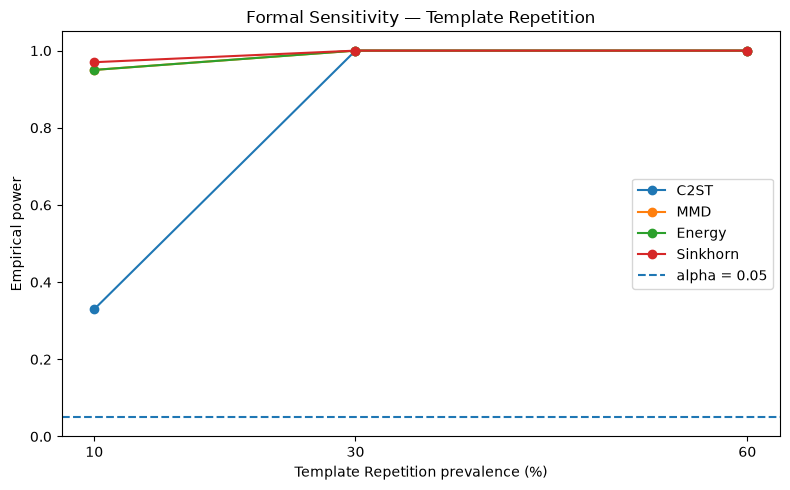

In [37]:
# sensitivity plot
plt.figure(figsize=(8,5))
for metric in ["C2ST","MMD","Energy","Sinkhorn"]:
    d=template_power_summary.loc[template_power_summary["metric"]==metric].sort_values("severity")
    plt.plot(d["severity"]*100,d["power"],marker="o",label=metric)

plt.axhline(TEMPLATE_ALPHA,linestyle="--",label="alpha = 0.05")
plt.xlabel("Template Repetition prevalence (%)")
plt.ylabel("Empirical power")
plt.title("Formal Sensitivity — Template Repetition")
plt.xticks([10,30,60])
plt.ylim(0,1.05)
plt.legend()
plt.tight_layout()
plt.show()

In [38]:
template_power_runs.to_csv(WEEK7_RESULTS_DIR/"template_formal_power_runs.csv",index=False)
template_power_summary.to_csv(WEEK7_RESULTS_DIR/"template_formal_power_summary.csv",index=False)
template_power_table.to_csv(WEEK7_RESULTS_DIR/"template_formal_power_table.csv",index=False)
template_prevalence_check.to_csv(WEEK7_RESULTS_DIR/"template_formal_sample_prevalence.csv",index=False)

print("Formal Template Repetition results saved.")

Formal Template Repetition results saved.


In [39]:
template_config={
    "defect":"Template Repetition",
    "experimental_unit":"individual SMS",
    "working_set":"same frozen 700 reference + 300 evaluation SMS split used by Over-Polished",
    "representation":"TF-IDF word 1-2 grams, max_features=5000, L2 normalized",
    "vectorizer_fit":"clean reference only",
    "repetition_design":"one fixed real template per class",
    "nested_prevalence":True,
    "severities":TEMPLATE_SEVERITIES,
    "repetitions":TEMPLATE_REPS,
    "pairs_per_repetition":TEMPLATE_N_PAIRS,
    "permutations":TEMPLATE_PERMUTATIONS,
    "alpha":TEMPLATE_ALPHA,
    "mmd_sigma":TEMPLATE_MMD_SIGMA,
    "sinkhorn_blur":TEMPLATE_SINKHORN_BLUR,
    "sinkhorn_blur_fraction":0.10,
    "clean_geometric_scale":TEMPLATE_CLEAN_SCALE,
    "sampling_seed_base":TEMPLATE_SAMPLE_BASE_SEED,
    "plan_seed":TEMPLATE_PLAN_SEED,
    "test_seed_base":TEMPLATE_TEST_BASE_SEED
}

with open(WEEK7_RESULTS_DIR/"template_formal_configuration.json","w") as f: json.dump(template_config,f,indent=4)

print("Configuration saved.")

Configuration saved.


In [40]:
import numpy as np,pandas as pd
from scipy.sparse import load_npz
from time import perf_counter
import importlib
import src.metrics as metrics
importlib.reload(metrics)
from src.metrics import sinkhorn_paired_permutation_test

TEMPLATE_REPS=200
TEMPLATE_N_PAIRS=100
TEMPLATE_PERMUTATIONS=100
TEMPLATE_ALPHA=0.05
TEMPLATE_SEVERITIES=[0.10,0.30,0.60]
TEMPLATE_SAMPLE_BASE_SEED=42
TEMPLATE_TEST_BASE_SEED=10000
TEMPLATE_SINKHORN_BLUR=0.1414213562373095

X_template={"clean":load_npz(DATA_DIR/"template_tfidf_clean.npz").toarray().astype(np.float32)}
for s in TEMPLATE_SEVERITIES: X_template[s]=load_npz(DATA_DIR/f"template_tfidf_{int(s*100)}pct.npz").toarray().astype(np.float32)

eval_meta=pd.read_csv(DATA_DIR/"template_repetition_formal_eval_ids.csv")
clean_ids=eval_meta["message_id"].astype(str).to_numpy()

template_plan=pd.read_csv(DATA_DIR/"template_repetition_formal_plan.csv")
affected={s:set(template_plan.loc[np.isclose(template_plan["severity"],s),"message_id"].astype(str)) for s in TEMPLATE_SEVERITIES}

print(X_template["clean"].shape)
print(TEMPLATE_SINKHORN_BLUR)
print(len(clean_ids))
print({s:len(affected[s]) for s in TEMPLATE_SEVERITIES})

(300, 5000)
0.1414213562373095
300
{0.1: 30, 0.3: 90, 0.6: 180}


## Sinkhorn permutation-null recovery

The original formal run stored Sinkhorn statistic, p-value and rejection
decision, but did not retain the permutation-null mean and standard
deviation. This recovery reruns Sinkhorn only, using the exact frozen
sampling and test seeds from the original experiment.

In [41]:
# recovery loop 
template_sinkhorn_recovery=[]
start=perf_counter()

for rep in range(TEMPLATE_REPS):
    rng=np.random.default_rng(TEMPLATE_SAMPLE_BASE_SEED+rep)
    idx=rng.choice(len(clean_ids),size=TEMPLATE_N_PAIRS,replace=False)
    sampled_ids=clean_ids[idx]
    P=X_template["clean"][idx]

    for severity in TEMPLATE_SEVERITIES:
        Q=X_template[severity][idx]
        n_affected=sum(mid in affected[severity] for mid in sampled_ids)

        t0=perf_counter()
        r=sinkhorn_paired_permutation_test(P,Q,blur=TEMPLATE_SINKHORN_BLUR,n_permutations=TEMPLATE_PERMUTATIONS,seed=TEMPLATE_TEST_BASE_SEED+rep,alpha=TEMPLATE_ALPHA)

        template_sinkhorn_recovery.append({
            "repetition":rep,"severity":severity,"n_pairs":TEMPLATE_N_PAIRS,
            "n_affected":n_affected,"sample_affected_rate":n_affected/TEMPLATE_N_PAIRS,
            "statistic":r["statistic"],"p_value":r["p_value"],"reject":r["reject"],
            "null_mean":r["null_mean"],"null_std":r["null_std"],
            "runtime_seconds":perf_counter()-t0
        })

    if (rep+1)%20==0: print(f"Completed {rep+1}/{TEMPLATE_REPS}")

template_sinkhorn_recovery=pd.DataFrame(template_sinkhorn_recovery)
print("Rows:",len(template_sinkhorn_recovery),"Expected:",600)
print("Runtime:",round((perf_counter()-start)/60,2),"minutes")

Completed 20/200
Completed 40/200
Completed 60/200
Completed 80/200
Completed 100/200
Completed 120/200
Completed 140/200
Completed 160/200
Completed 180/200
Completed 200/200
Rows: 600 Expected: 600
Runtime: 30.24 minutes


In [42]:
template_old=pd.read_csv(WEEK7_RESULTS_DIR/"template_formal_power_runs.csv")
template_old_sink=template_old.loc[template_old["metric"]=="Sinkhorn"].copy()

template_check=template_old_sink.merge(
    template_sinkhorn_recovery,
    on=["repetition","severity"],
    suffixes=("_old","_new")
)

template_check["stat_diff"]=np.abs(template_check["statistic_old"]-template_check["statistic_new"])
template_check["p_diff"]=np.abs(template_check["p_value_old"]-template_check["p_value_new"])
template_check["reject_same"]=template_check["reject_old"]==template_check["reject_new"]

print("Rows compared:",len(template_check))
print("Max statistic difference:",template_check["stat_diff"].max())
print("Max p-value difference:",template_check["p_diff"].max())
print("Same reject decisions:",template_check["reject_same"].all())

Rows compared: 600
Max statistic difference: 9.71445146547012e-17
Max p-value difference: 5.551115123125783e-17
Same reject decisions: True


In [43]:
#observed minus null 
template_sinkhorn_recovery["obs_minus_null"]=template_sinkhorn_recovery["statistic"]-template_sinkhorn_recovery["null_mean"]

template_sinkhorn_gap=template_sinkhorn_recovery.groupby("severity").agg(
    mean_statistic=("statistic","mean"),
    mean_null=("null_mean","mean"),
    mean_obs_minus_null=("obs_minus_null","mean"),
    std_obs_minus_null=("obs_minus_null","std"),
    power=("reject","mean")
).reset_index()

display(template_sinkhorn_gap)

,severity,mean_statistic,mean_null,mean_obs_minus_null,std_obs_minus_null,power
0,0.1,0.092768,0.049092,0.043676,0.012655,0.97
1,0.3,0.280810,0.134869,0.145941,0.018899,1.00
2,0.6,0.555894,0.253104,0.302790,0.019969,1.00


In [44]:
template_sinkhorn_recovery.to_csv(WEEK7_RESULTS_DIR/"template_formal_sinkhorn_power_runs_enriched.csv",index=False)
template_sinkhorn_gap.to_csv(WEEK7_RESULTS_DIR/"template_formal_sinkhorn_null_gap.csv",index=False)


The Template repetition experiment was formalized to transition the project's original dry-run pilot into a reproducible, and comparable benchmark. The formalization preserves the core exact-repetition mechanism—replacing real SMS messages with class-specific templates—while establishing a fixed nested defect plan, a paired experimental design, clean-only representation fitting, and reference-derived metric scales. Evaluated using a 5,000-dimensional TF-IDF representation, exact repetition causes probability mass to concentrate around specific lexical patterns. This structural shift proved highly detectable by distributional metrics even at low prevalence, while highlighting key trade-offs in classifier capacity and computational efficiency.

### Transition from pilot to formal experiment

To align Template repetition with later semantic defect benchmarks, several preliminary design choices from the pilot were replaced:

* **Paired experimental design:** Rather than drawing P (clean) and Q (defective) from disjoint original rows, every defective SMS ($Q_i$) was paired with its exact clean counterpart ($P_i$). Unaffected observations satisfy $P_i = Q_i$, while affected observations replace original text with the class-specific template.
* **Frozen dataset split and class balance:** Evaluated on the frozen split of 700 clean reference messages (used strictly for vectorizer fitting and metric scaling) and 300 clean evaluation messages (260 ham, 40 spam).
* **Fixed nested defect plan:** Within each class, a single real reference message was chosen as the template. Affected indices were ordered once and nested across severities ($A_{10\%} \subset A_{30\%} \subset A_{60\%}$), exactly preserving class proportions:
  * 10% prevalence: 26 ham, 4 spam (30 total)
  * 30% prevalence: 78 ham, 12 spam (90 total)
  * 60% prevalence: 156 ham, 24 spam (180 total)
* **Leakage-free TF-IDF vectorization:** Word-level TF-IDF (unigrams and bigrams, 5,000 max features, L2-normalized) was fitted exclusively on the 700 clean reference messages and frozen prior to transforming evaluation data.
* **Clean-derived geometric scaling:** Removed the pilot's arbitrary MMD sigma of 1.0. Based on the clean reference median pairwise Euclidean distance of 1.41421356 (reflecting near-orthogonality in L2-normalized TF-IDF space), scales were frozen at:
  * MMD sigma ($\sigma_{\text{MMD}}$): 1.41421356
  * Sinkhorn blur ($blur_{\text{Sinkhorn}}$): 0.14142136 ($0.10 \times \text{median}$)
* **Protocol standardization:** Standardized to 200 repetitions, 100 sampled pairs per repetition, 100 permutations, and $\alpha = 0.05$.


### Clean-null calibration and effective prevalence

* **Null calibration:** A disjoint clean-null experiment (preserving class composition without identical $P_i = Q_i$ pairs) confirmed proper Type I error control:
  * C2ST: 0.030 Type I error (mean p-value 0.519, median 0.540)
  * Energy distance: 0.045 Type I error (mean p-value 0.520, median 0.550)
  * MMD: 0.045 Type I error (mean p-value 0.515, median 0.550)
  * Sinkhorn divergence: 0.045 Type I error (mean p-value 0.537, median 0.550)
* **Effective prevalence tracking:** Repeated sampling of 100 pairs from the 300-message pool yielded mean affected sample rates of 10.08% (10% target), 30.08% (30% target), and 59.79% (60% target).


### Empirical power results

* **Comparative sensitivity across severities:**
  * **10% prevalence:** Distributional metrics demonstrated strong detection, whereas linear C2ST lagged behind:
    * C2ST power: 0.33 (66/200 rejections)
    * Energy distance power: 0.95 (190/200 rejections)
    * MMD power: 0.95 (190/200 rejections)
    * Sinkhorn divergence power: 0.97 (194/200 rejections)
  * **30% prevalence:** Complete benchmark saturation; all four metrics achieved 1.00 power (200/200 rejections).
  * **60% prevalence:** Complete benchmark saturation; all four metrics achieved 1.00 power (200/200 rejections).
* **Historical comparison with pilot values:**
  * Pilot results: C2ST = 0.11 (10%), 0.85 (30%), 1.00 (60%); Energy = 1.00 across all; MMD = 1.00 across all.
  * Formalized results replace pilot metrics for official cross-defect benchmarking due to protocol rigor, though pilot records remain as historical development artifacts.


### Metric behavior and computational complexity

* **Lexical concentration sensitivity:** Exact template repetition creates concentrated probability mass in TF-IDF space. MMD, Energy, and Sinkhorn react strongly to this localized mass shift even at low prevalence.
* **Linear classifier limitations:** Linear C2ST achieved only 0.33 power at 10% prevalence because concentrated duplicate clusters do not necessarily yield a simple global linear hyper-plane between clean and defective samples.
* **Absence of paired Sinkhorn blind spot:** In contrast to its weak or non-monotonic performance on stylistic/semantic defects, Sinkhorn achieved 0.97 power at 10% prevalence. This proves that paired Sinkhorn sensitivity is fully functional when defect geometry significantly alters empirical transport arrangements.
* **Execution runtime trade-offs:** At 10% prevalence, mean runtime per test demonstrated a severe computational disparity:
  * C2ST: $\approx 0.05$ seconds
  * Energy distance: $\approx 0.07$ seconds
  * MMD: $\approx 0.08$ seconds
  * Sinkhorn divergence: $\approx 2.85$ seconds (requiring 30.6 minutes for the full 200-repetition power experiment)


### Conceptual limitations and future directions

* **Confounding variables in defect definition:** Inserting an exact real message reduces population diversity but simultaneously alters lexical frequencies, phrase distributions, local TF-IDF density, and topic balance. Thus, high metric power reflects sensitivity to the combined exact-repetition intervention rather than isolated mode collapse.
* **Role in distributional precision and recall:** Template repetition serves as a prime candidate for future Precision and Recall for Distributions (PRD) analysis, which can formally decouple whether probability mass concentration causes a loss of support coverage versus changes in sample quality.